In [1]:
import pandas as pd
from google.colab import files
import io

uploaded = files.upload()

file_name = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
)

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors.csv
Dataset loaded successfully!
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Explanation: This code uploads the CSV file, reads it into a Pandas DataFrame, displays the number of rows and columns, and shows the first five records.

In [2]:
target = "Exam_Score"

X = df.drop(columns=[target])
y = df[target]

print("Problem Type: Regression")
print("Target Variable:", target)
print("Number of Features:", X.shape[1])
print("Number of Records:", X.shape[0])
print("Target Data Type:", y.dtype)

Problem Type: Regression
Target Variable: Exam_Score
Number of Features: 19
Number of Records: 6607
Target Data Type: int64


Explanation: The target variable is Exam_Score. The input features are the remaining 19 columns. Since the target contains numerical exam scores, this is a regression problem.

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Summary:")
print(df["Exam_Score"].describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence             

Explanation: This cell checks column data types, missing values, duplicate rows, and the statistical summary of exam scores. This helps us identify data-quality issues before training the models.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5285, 19)
Testing Features: (1322, 19)
Training Target: (5285,)
Testing Target: (1322,)


Explanation: The dataset is divided into 80% training data and 20% testing data. Models learn from the training set, while the test set is reserved for evaluating predictions on unseen data. random_state=42 makes the split reproducible.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical Features: 6
Categorical Features: 13
Preprocessing pipeline created successfully.


Explanation:
- SimpleImputer(strategy="median") fills missing numerical values using the median.
- SimpleImputer(strategy="most_frequent") fills missing categorical values using the most frequent category.
- StandardScaler() scales numerical features for Linear Regression.
- OneHotEncoder() converts categorical values into numerical representations.
- ColumnTransformer() applies the appropriate preprocessing to each type of feature.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

print("Three regression models are ready:")
for model_name in models:
    print(model_name)

Three regression models are ready:
Linear Regression
Decision Tree Regressor
Random Forest Regressor


Explanation :
1. Linear Regression: Predicts exam scores by learning linear relationships between features and the target.
2. Decision Tree Regressor: Predicts scores using decision rules based on feature values.
3. Random Forest Regressor: Combines predictions from multiple decision trees to improve predictive performance and reduce the instability of a single tree.
We use three different models so their predictive performance can be compared fairly

In [7]:
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

results = []
trained_models = {}

for name, model in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train using training data only
    pipeline.fit(X_train, y_train)

    # Predictions on training and testing data
    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    # Training metrics
    train_mae = mean_absolute_error(
        y_train, train_predictions
    )
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )
    train_r2 = r2_score(y_train, train_predictions)

    # Testing metrics
    test_mae = mean_absolute_error(
        y_test, test_predictions
    )
    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )
    test_r2 = r2_score(y_test, test_predictions)

    results.append({
        "Model": name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R2": train_r2,
        "Test R2": test_r2
    })

    trained_models[name] = pipeline

    print(f"\n{name}")
    print(f"Test MAE: {test_mae:.4f}")
    print(f"Test RMSE: {test_rmse:.4f}")
    print(f"Test R2: {test_r2:.4f}")

results_df = pd.DataFrame(results)

print("\nAll models trained and evaluated successfully.")
display(results_df.round(4))


Linear Regression
Test MAE: 0.4524
Test RMSE: 1.8044
Test R2: 0.7696

Decision Tree Regressor
Test MAE: 1.5385
Test RMSE: 2.6232
Test R2: 0.5132

Random Forest Regressor
Test MAE: 1.0463
Test RMSE: 2.1032
Test R2: 0.6871

All models trained and evaluated successfully.


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.4985,0.4524,2.0852,1.8044,0.7173,0.7696
1,Decision Tree Regressor,1.0759,1.5385,1.9862,2.6232,0.7435,0.5132
2,Random Forest Regressor,0.6379,1.0463,1.6002,2.1032,0.8335,0.6871


Explanation: Each model is fitted on the training set and evaluated on the separate test set. We calculate MAE, RMSE, and R² for both sets to compare predictive accuracy and examine possible overfitting.


In [8]:
comparison = results_df[
    ["Model", "Test MAE", "Test RMSE", "Test R2"]
].copy()

comparison = comparison.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

comparison.insert(
    0,
    "Rank",
    range(1, len(comparison) + 1)
)

print("MODEL COMPARISON TABLE")
display(comparison.round(4))

MODEL COMPARISON TABLE


,Rank,Model,Test MAE,Test RMSE,Test R2
0,1,Linear Regression,0.4524,1.8044,0.7696
1,2,Random Forest Regressor,1.0463,2.1032,0.6871
2,3,Decision Tree Regressor,1.5385,2.6232,0.5132


Explanation : This table compares all three models using their test-set results. Models are ranked by RMSE, with the lowest RMSE receiving the first rank. MAE and R² are also considered when interpreting the results.

In [9]:
print("OVERFITTING AND UNDERFITTING CHECK\n")

for _, row in results_df.iterrows():

    print(row["Model"])
    print(f"Training R2: {row['Train R2']:.4f}")
    print(f"Testing R2:  {row['Test R2']:.4f}")

    r2_gap = row["Train R2"] - row["Test R2"]

    if r2_gap > 0.15:
        print("Interpretation: Possible overfitting.")
    elif row["Train R2"] < 0.20 and row["Test R2"] < 0.20:
        print("Interpretation: Possible underfitting.")
    else:
        print("Interpretation: No strong warning from this simple check.")

    print("-" * 40)

OVERFITTING AND UNDERFITTING CHECK

Linear Regression
Training R2: 0.7173
Testing R2:  0.7696
Interpretation: No strong warning from this simple check.
----------------------------------------
Decision Tree Regressor
Training R2: 0.7435
Testing R2:  0.5132
Interpretation: Possible overfitting.
----------------------------------------
Random Forest Regressor
Training R2: 0.8335
Testing R2:  0.6871
Interpretation: No strong warning from this simple check.
----------------------------------------


Explanation : Overfitting may occur when a model performs much better on training data than on unseen testing data. Underfitting may occur when a model performs poorly on both. This is a simple diagnostic, not a definitive test; the size of the performance gap should be interpreted in context

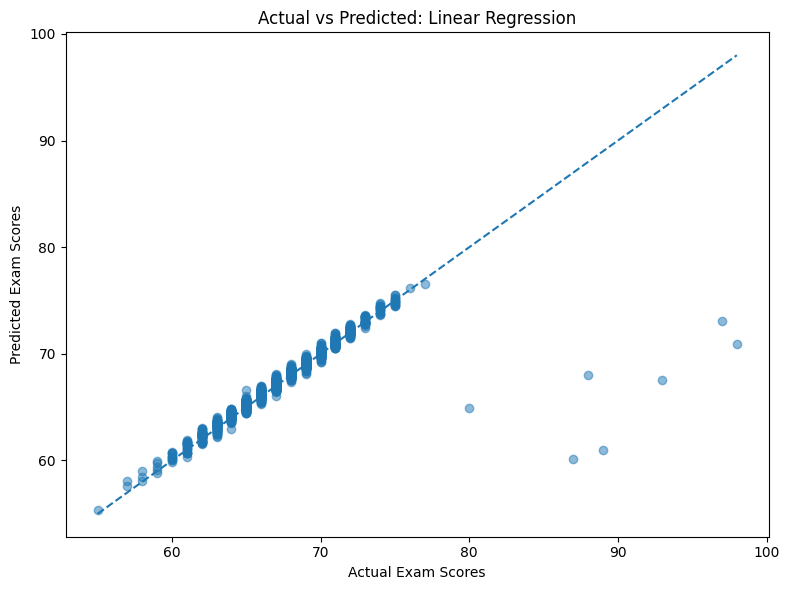

In [10]:
import matplotlib.pyplot as plt

best_model_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.show()

Explanation : The scatter plot compares actual exam scores with predicted scores. Points closer to the diagonal reference line indicate more accurate predictions. Points farther away represent larger prediction errors.

In [11]:
best_row = comparison.iloc[0]
best_name = best_row["Model"]

best_result = results_df[
    results_df["Model"] == best_name
].iloc[0]

print("FINAL CONCLUSION")
print("=" * 50)

print(
    f"The best-performing model based on test RMSE is "
    f"{best_name}."
)

print(f"Test MAE: {best_result['Test MAE']:.4f}")
print(f"Test RMSE: {best_result['Test RMSE']:.4f}")
print(f"Test R2: {best_result['Test R2']:.4f}")

print(
    "\nThe main selection metric is RMSE because it "
    "measures prediction error and penalizes large errors."
)

print(
    "\nMAE provides an understandable average error in exam-score "
    "points, while R2 indicates how much variation is explained."
)

r2_gap = best_result["Train R2"] - best_result["Test R2"]

if r2_gap > 0.15:
    print(
        "\nThe selected model shows a possible overfitting warning "
        "because its training R2 is noticeably higher than its test R2."
    )
elif (
    best_result["Train R2"] < 0.20
    and best_result["Test R2"] < 0.20
):
    print(
        "\nThe selected model may be underfitting because its "
        "training and test R2 scores are both low."
    )
else:
    print(
        "\nThe simple R2-gap check does not show a strong warning "
        "of overfitting. Further validation may still be useful."
    )

FINAL CONCLUSION
The best-performing model based on test RMSE is Linear Regression.
Test MAE: 0.4524
Test RMSE: 1.8044
Test R2: 0.7696

The main selection metric is RMSE because it measures prediction error and penalizes large errors.

MAE provides an understandable average error in exam-score points, while R2 indicates how much variation is explained.

The simple R2-gap check does not show a strong warning of overfitting. Further validation may still be useful.


Explanation : This cell selects the model with the lowest test RMSE and prints its evaluation metrics. It also produces a preliminary interpretation of the training–testing performance gap

# Assignment No. 4: Machine Learning Model Application & Evaluation

## 1. Problem Definition

The Student Performance Factors dataset contains 6,607 records and 20 columns. It includes information about students' study hours, attendance, previous scores, sleep hours, tutoring sessions, and other factors related to academic performance.

The objective is to predict students' exam scores using Machine Learning.

- **Problem Type:** Regression
- **Features (X):** The 19 input columns other than Exam_Score
- **Target (y):** Exam_Score

## 2. Train-Test Split

The dataset was divided into 80% training data and 20% testing data. The training set was used to fit the models, while the testing set was used to evaluate their performance on unseen records.

## 3. Data Preprocessing

Missing numerical values were handled using median imputation, and missing categorical values were handled using most-frequent imputation. Numerical features were standardized, and categorical features were converted into numerical representations using one-hot encoding. Preprocessing was fitted using training data only.

## 4. Machine Learning Models

Three regression models were applied:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

## 5. Evaluation Metrics

Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²) were used to evaluate and compare the models. Lower MAE and RMSE values indicate smaller prediction errors, while a higher R² generally indicates better explanatory performance.

## 6. Model Comparison

The models were compared using their actual test-set results. The comparison table and prediction plot are included in the notebook.

## 7. Final Conclusion

The best-performing model was identified using the test RMSE, with MAE and R² considered as supporting metrics. RMSE was selected as the main metric because it penalizes larger prediction errors. The difference between training and testing performance was also examined for possible overfitting or underfitting.

The final model selection and conclusions are based on the results produced by the executed notebook.